# Analisis exploratorio: datos de desarrollo

Carlos Zambrano Figueroa | Grupo 11

Este notebook utiliza solo las 3.539 filas de desarrollo. No entrena modelos ni evalua la reserva final. Genera la misma evidencia que utiliza `docs/analisis_datos.md`.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / 'src/data_processing.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src/data_processing.py').exists():
    raise RuntimeError('Ejecutar desde la raiz del repositorio o notebooks/')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from src.data_processing import FEATURES, load_development
from src.eda import FIGURES, run

development, folds = load_development()
assert len(development) == 3539
summary = run()
print('Filas analizadas:', summary['rows'])
print('Predictores permitidos:', len(FEATURES))
print('Reserva final: sin evaluacion')


Filas analizadas: 3539
Predictores permitidos: 18
Reserva final: sin evaluacion


## Calidad, distribuciones y representacion

Las tablas se obtienen de `results/metrics/eda.json`. No se muestran registros individuales ni se carga la reserva como ejemplo.


In [2]:
display(pd.Series(summary['class_counts'], name='Estudiantes').to_frame())
print('Celdas nulas:', summary['missing_cells'])
print('Duplicados exactos:', summary['exact_duplicates'])
print('Duplicados en predictores:', summary['duplicate_feature_rows'])
print('Violaciones de rango:', sum(summary['range_check_violations'].values()))
display(pd.DataFrame(summary['numeric']).T)


,Estudiantes
Dropout,1137
Enrolled,635
Graduate,1767


Celdas nulas: 0
Duplicados exactos: 0
Duplicados en predictores: 0
Violaciones de rango: 0


,count,mean,std,min,25%,50%,75%,max,iqr_lower,iqr_upper,iqr_flags
Application order,3539.0,1.727042,1.307274,0.0,1.0,1.0,2.0,9.0,-0.50,3.50,431.0
Previous qualification (grade),3539.0,132.684713,13.202248,95.0,125.0,133.1,140.0,190.0,102.50,162.50,135.0
Admission grade,3539.0,126.876745,14.530706,95.0,117.8,126.0,134.9,190.0,92.15,160.55,68.0
Age at enrollment,3539.0,23.249506,7.605164,17.0,19.0,20.0,25.0,70.0,10.00,34.00,358.0


## 1. Clases observadas


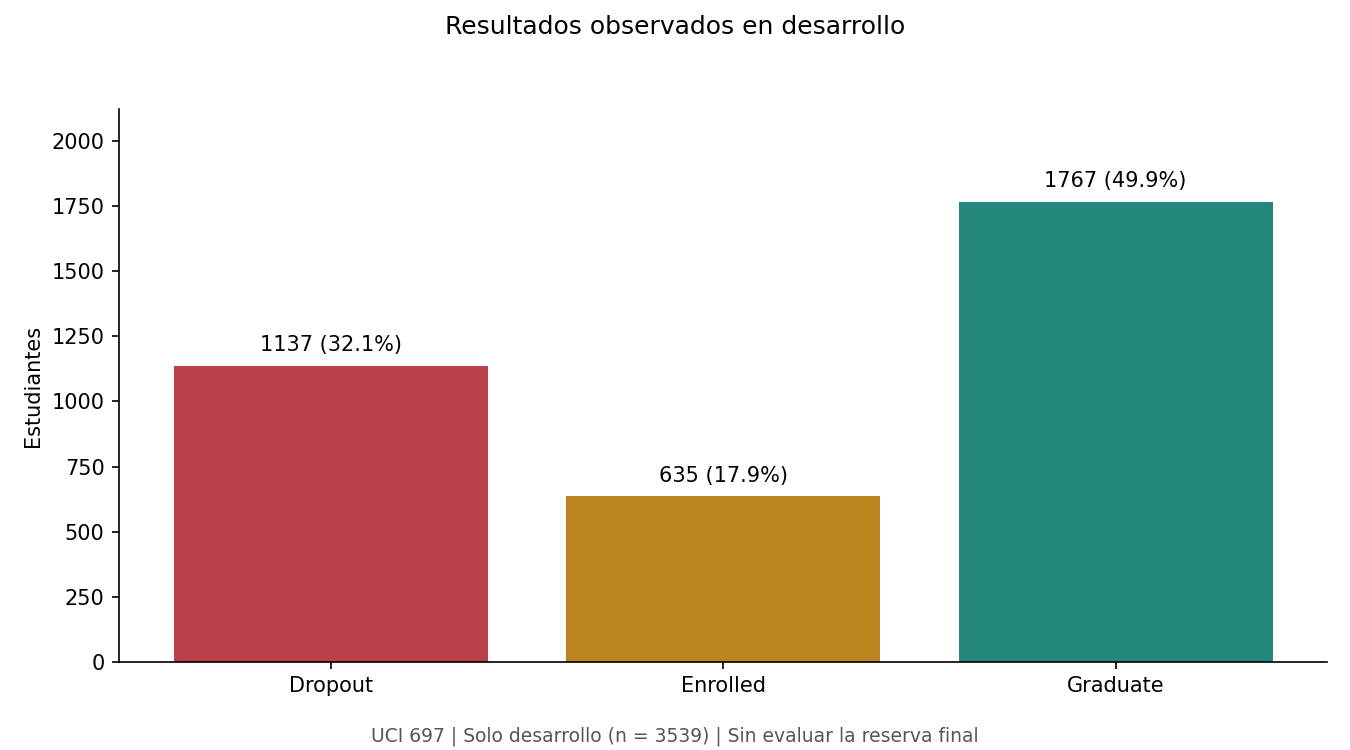

In [3]:
display(Image(filename=str(ROOT / 'results/figures' / FIGURES[0][0])))


## 2. Distribuciones numericas


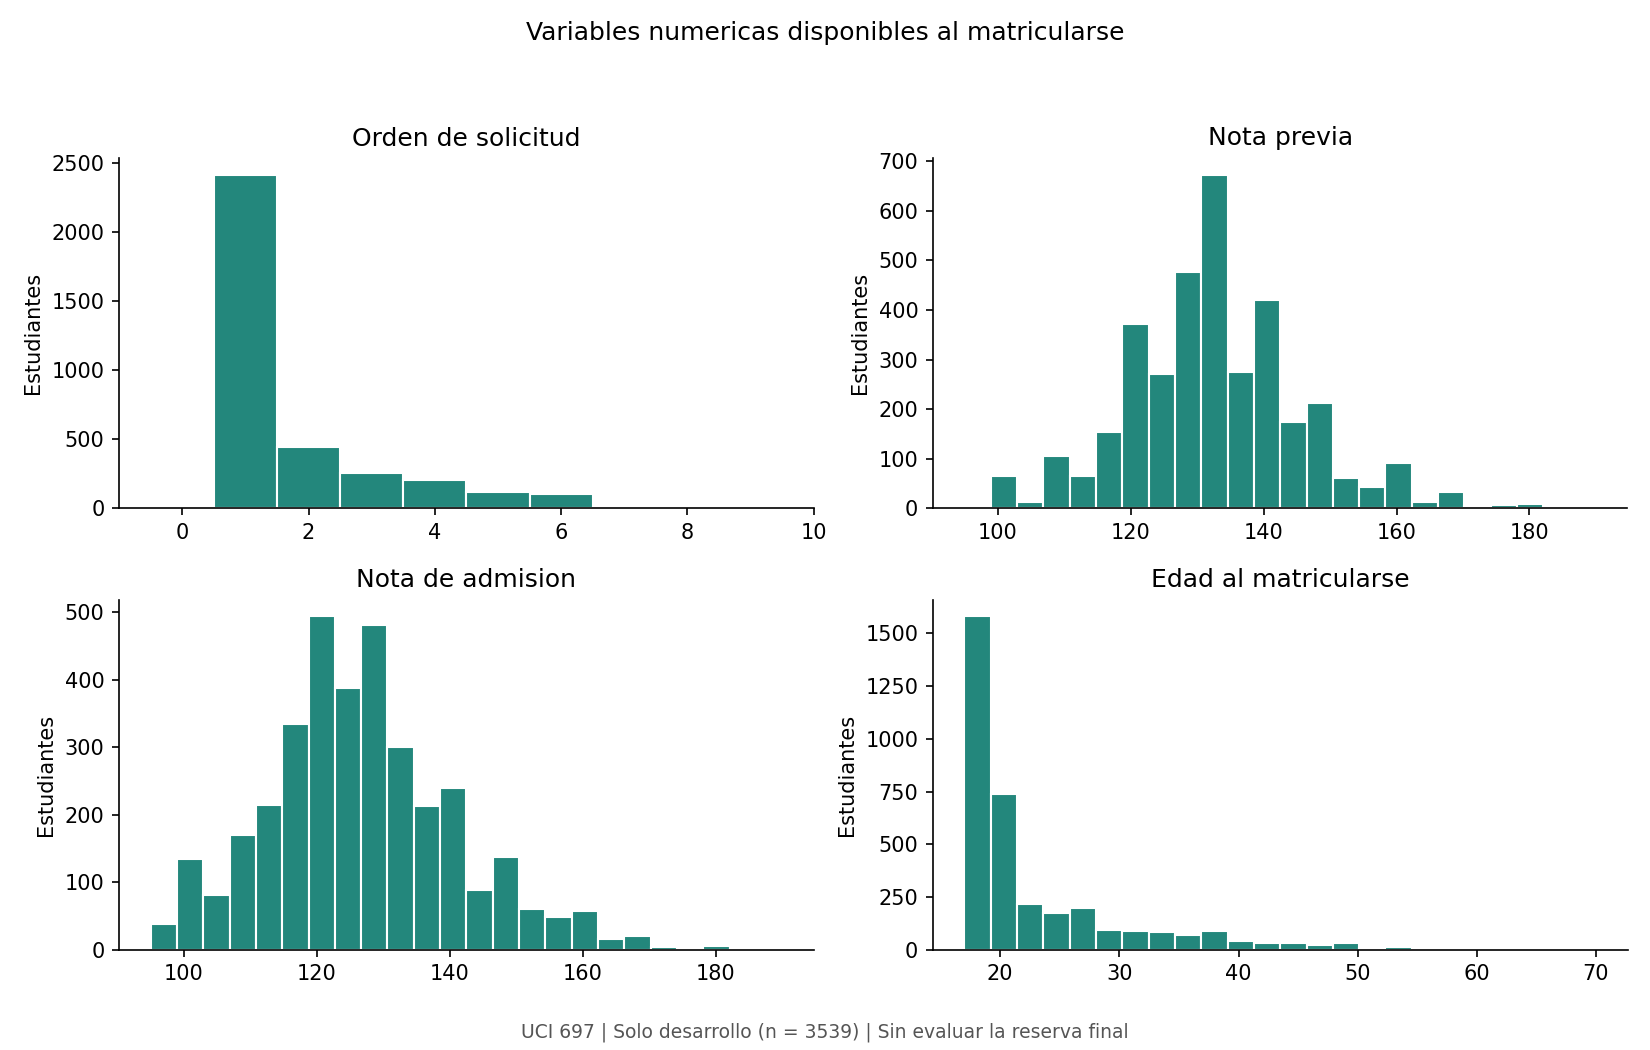

In [4]:
display(Image(filename=str(ROOT / 'results/figures' / FIGURES[1][0])))


## 3. Notas y edad por clase


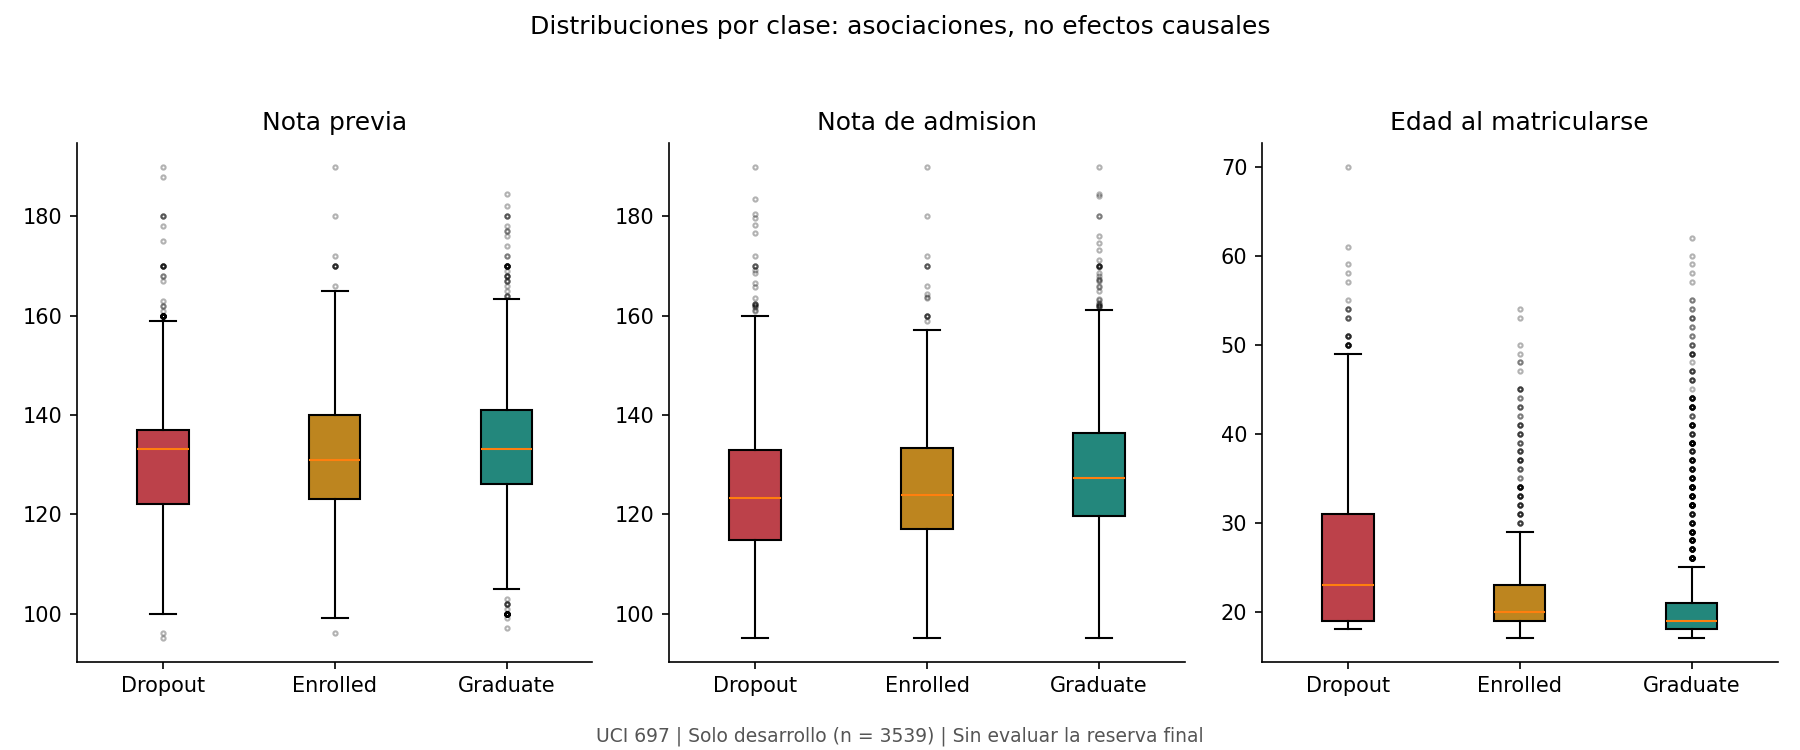

In [5]:
display(Image(filename=str(ROOT / 'results/figures' / FIGURES[2][0])))


## 4. Composicion por edad


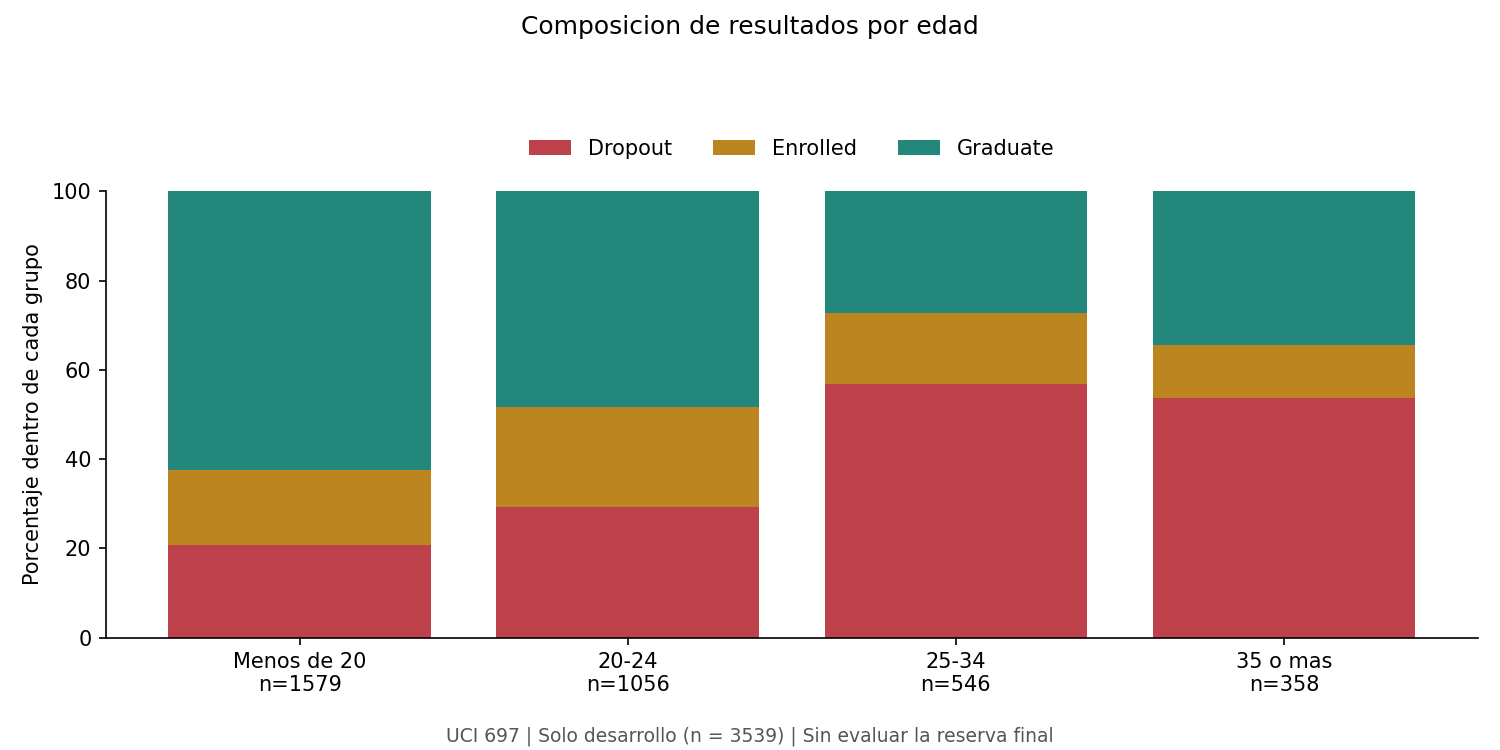

In [6]:
display(Image(filename=str(ROOT / 'results/figures' / FIGURES[3][0])))


## 5. Correlaciones numericas


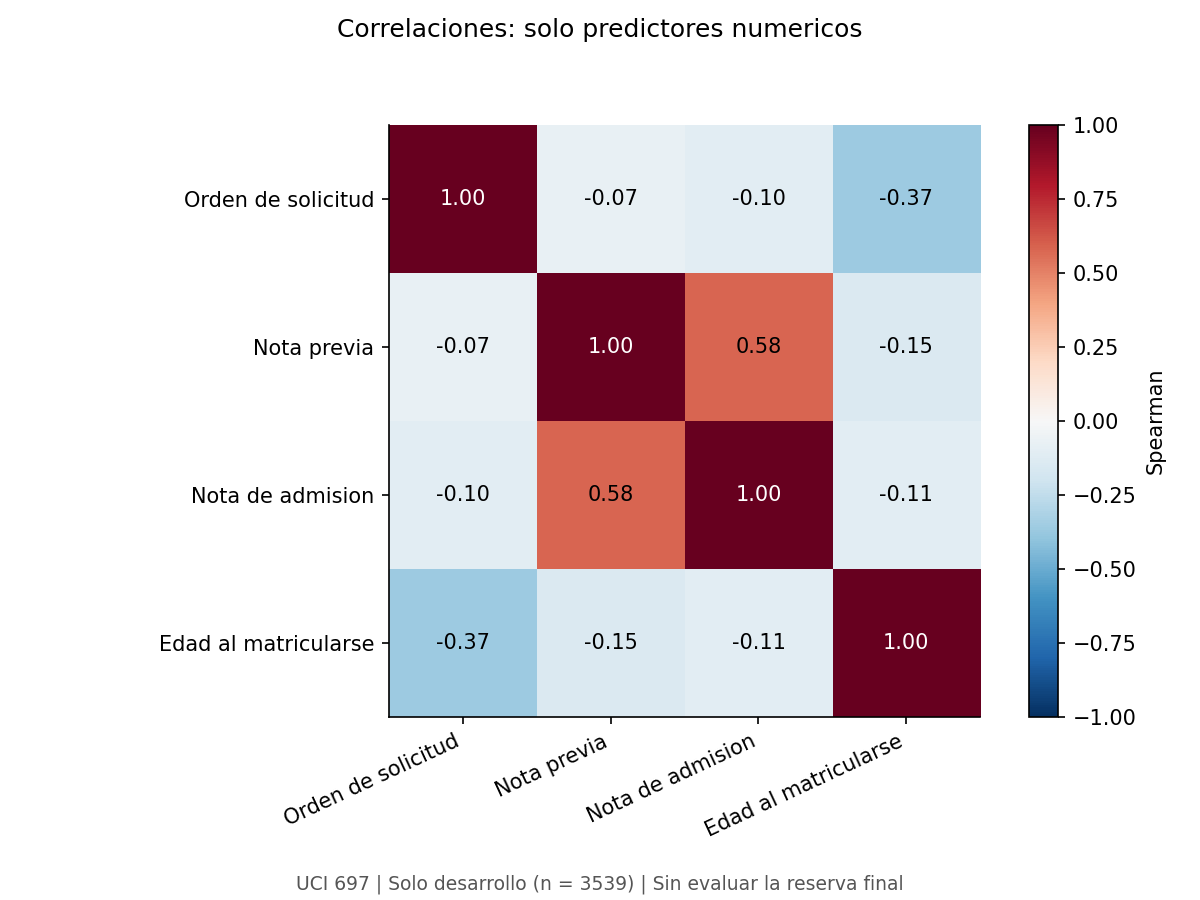

In [7]:
display(Image(filename=str(ROOT / 'results/figures' / FIGURES[4][0])))


## 6. Categorias nominales


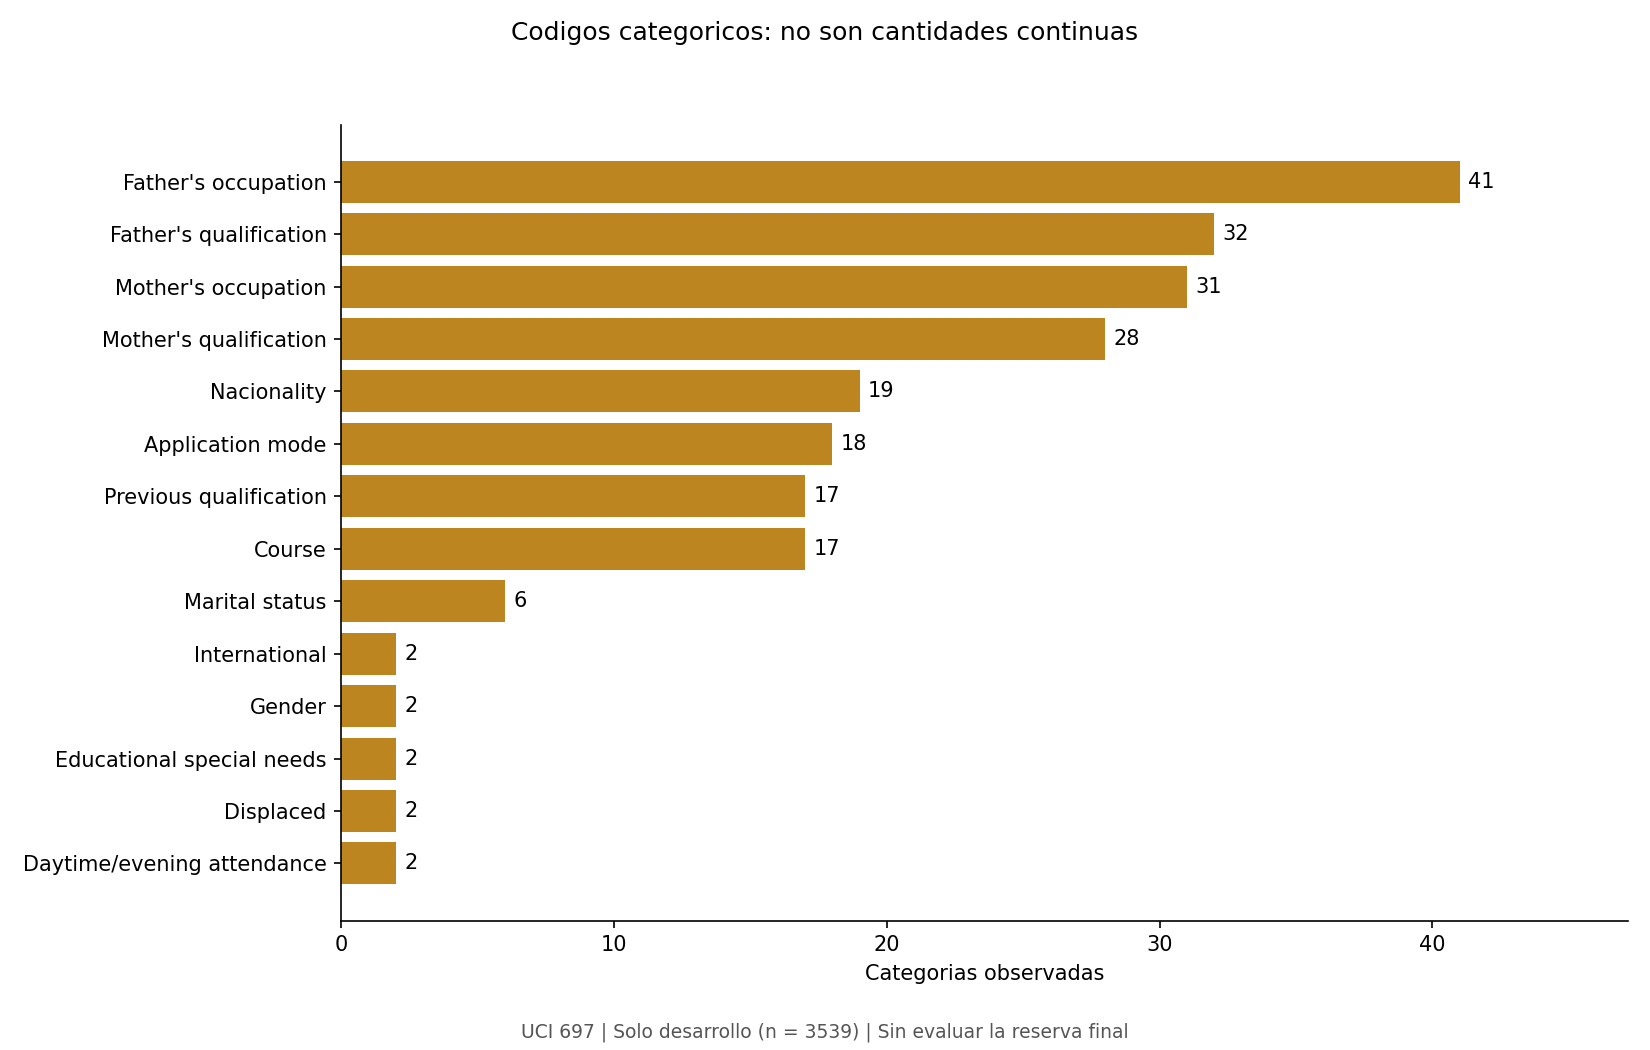

In [8]:
display(Image(filename=str(ROOT / 'results/figures' / FIGURES[5][0])))


## 7. Representacion de subgrupos


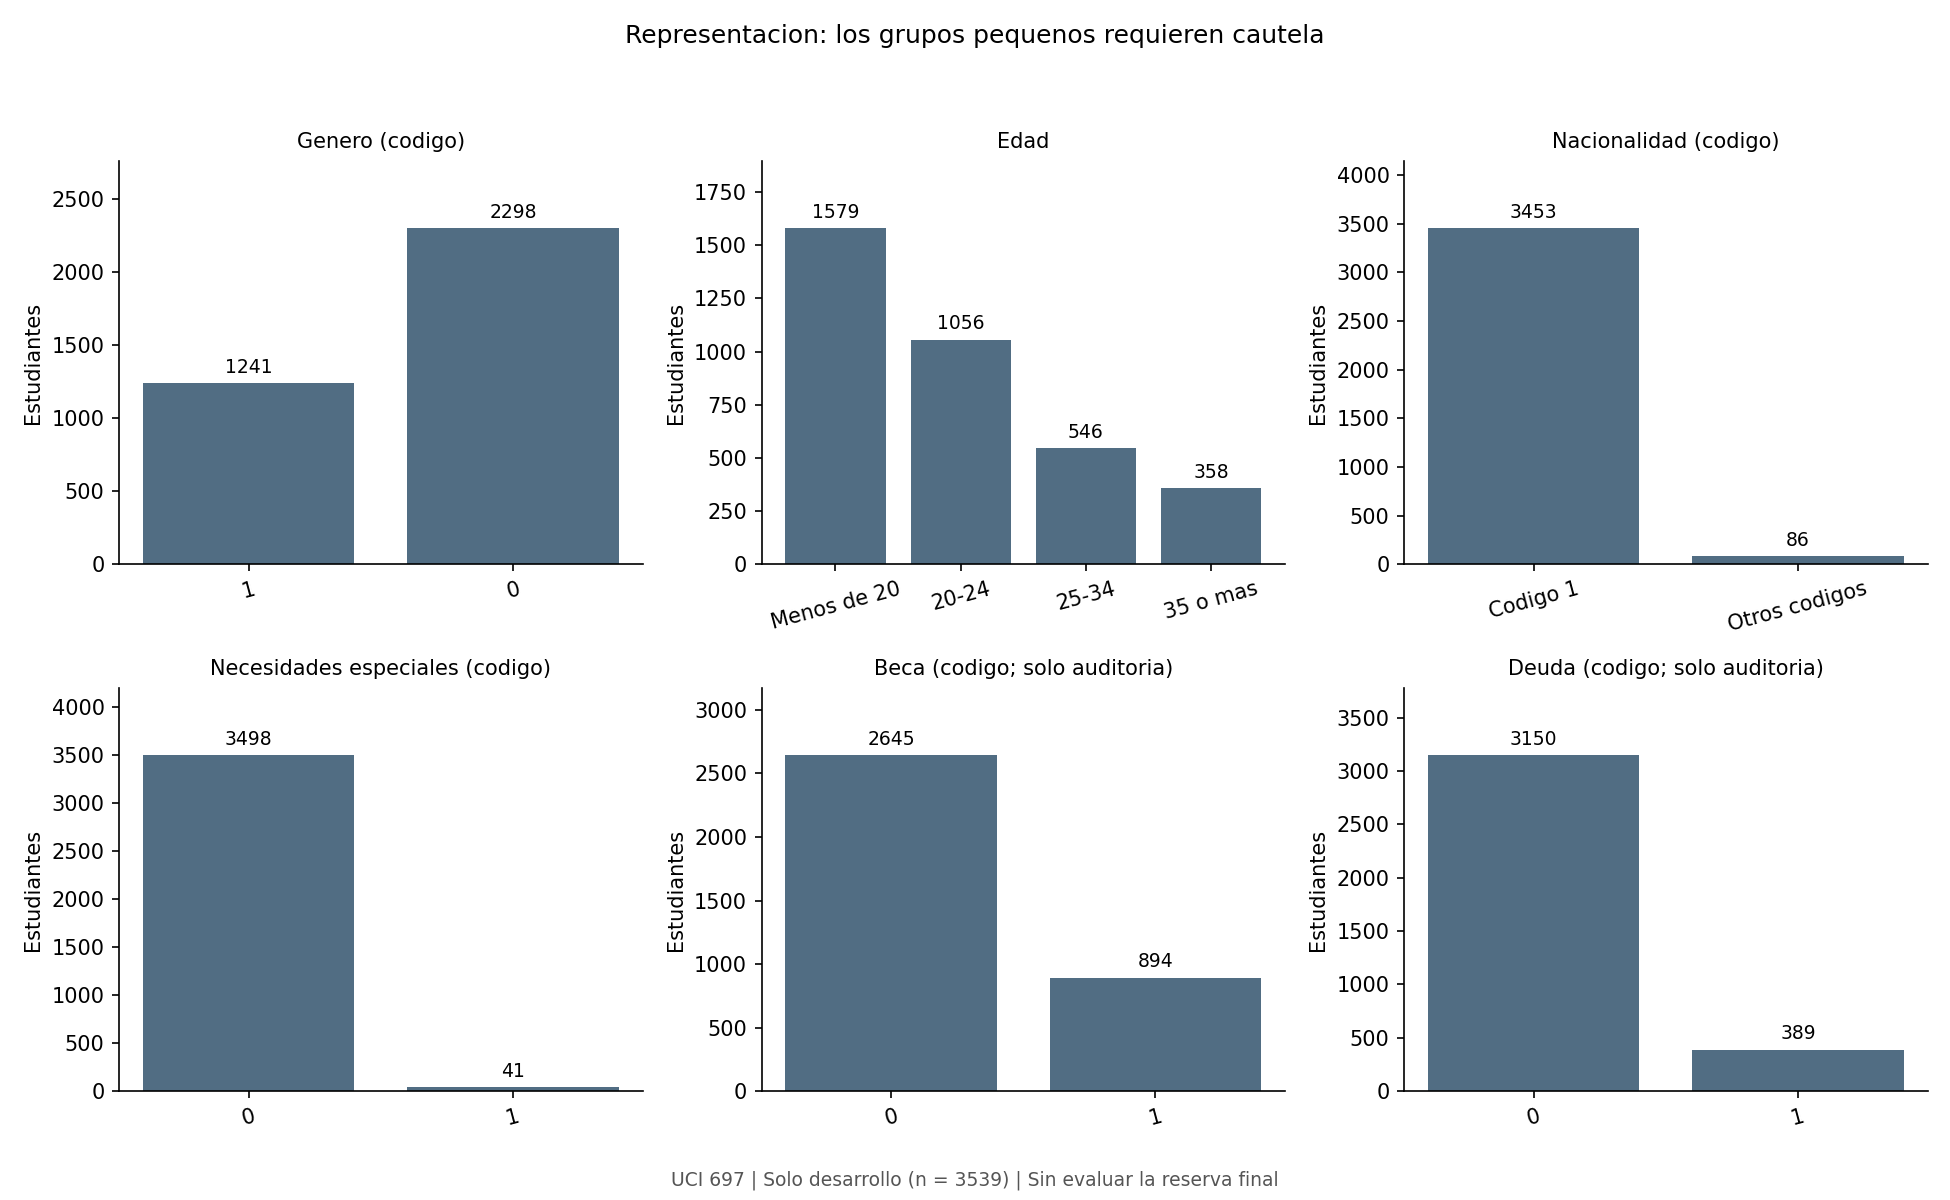

In [9]:
display(Image(filename=str(ROOT / 'results/figures' / FIGURES[6][0])))


## Interpretacion y decisiones

- Enrolled es un estado no resuelto, no un caso confirmado de exito o abandono.
- Se mantienen 18 predictores de matricula; los indicadores semestrales y seis variables de temporalidad no confirmada quedan fuera del modelo.
- Los valores fuera de 1,5 IQR se senalan, pero no se eliminan automaticamente.
- Las correlaciones se calculan solo entre predictores numericos. Los codigos categoricos no son cantidades.
- La distribucion de subgrupos es descriptiva: no demuestra equidad del modelo. Beca y deuda se describen solo para auditoria.
- Las transformaciones se ajustaran dentro de los folds de entrenamiento.
- Los resultados son asociaciones de una muestra institucional portuguesa, no conclusiones causales ni validacion en Ecuador.

Los conteos por categoria y subgrupo y las conclusiones se presentan en `docs/analisis_datos.md`. La referencia y la licencia estan en `data/README.md`.
